In [1]:
pip install torch pandas matplotlib scikit-learn

In [2]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler

In [6]:
# Load the dataset
df = pd.read_csv("/content/house_price_regression_dataset.csv")

# Display the first five rows
print(df.head())

# Display column names
print("Columns:", df.columns.tolist())

   Area_sqft  Bedrooms  Bathrooms  House_Age_Years  Price_Lakhs
0        600         1          1               20           18
1        750         1          1               15           22
2        800         2          1               12           25
3        900         2          2               10           30
4       1000         2          2                8           34
Columns: ['Area_sqft', 'Bedrooms', 'Bathrooms', 'House_Age_Years', 'Price_Lakhs']


In [8]:
# Input: House area
X = df[["Area_sqft"]].values

# Output: House price
y = df[["Price_Lakhs"]].values

print("Input Shape:", X.shape)
print("Output Shape:", y.shape)

Input Shape: (20, 1)
Output Shape: (20, 1)


In [9]:
# Create scalers
scaler_X = MinMaxScaler()
scaler_y = MinMaxScaler()

# Normalize input and output
X_scaled = scaler_X.fit_transform(X)
y_scaled = scaler_y.fit_transform(y)

# Convert into PyTorch tensors
X_tensor = torch.tensor(X_scaled, dtype=torch.float32)
y_tensor = torch.tensor(y_scaled, dtype=torch.float32)

print("Data normalization completed!")

Data normalization completed!


In [10]:
class RegressionModel(nn.Module):

    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(1, 16),
            nn.ReLU(),
            nn.Linear(16, 1)
        )

    def forward(self, x):
        return self.network(x)


# Create the model
model = RegressionModel()

print(model)

RegressionModel(
  (network): Sequential(
    (0): Linear(in_features=1, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)


In [11]:
# Loss function
criterion = nn.MSELoss()

# Optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.01
)

# Number of iterations
epochs = 1000

# Store training loss
loss_history = []

# Training loop
for epoch in range(epochs):

    # Forward propagation
    predictions = model(X_tensor)

    # Calculate loss
    loss = criterion(predictions, y_tensor)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()

    # Update weights
    optimizer.step()

    # Save loss
    loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch [{epoch + 1}/{epochs}], "
            f"Loss: {loss.item():.6f}"
        )

print("\nModel training completed!")

Epoch [100/1000], Loss: 0.000853
Epoch [200/1000], Loss: 0.000190
Epoch [300/1000], Loss: 0.000117
Epoch [400/1000], Loss: 0.000110
Epoch [500/1000], Loss: 0.000110
Epoch [600/1000], Loss: 0.000110
Epoch [700/1000], Loss: 0.000110
Epoch [800/1000], Loss: 0.000110
Epoch [900/1000], Loss: 0.000110
Epoch [1000/1000], Loss: 0.000113

Model training completed!


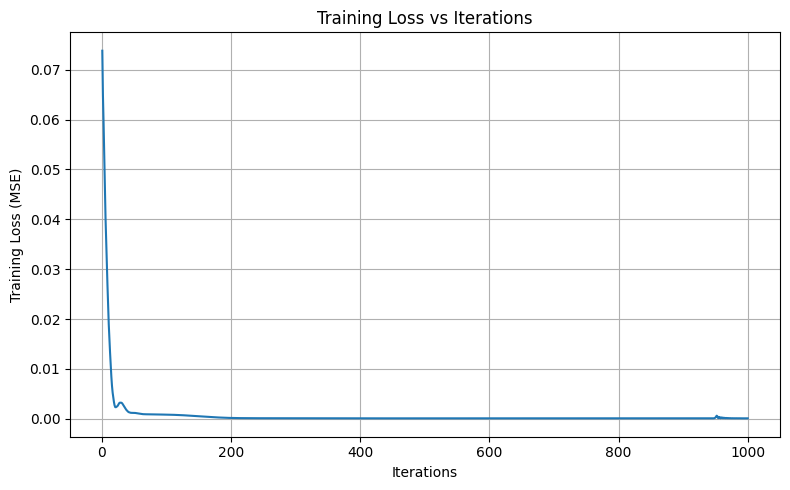

In [12]:
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, epochs + 1),
    loss_history
)

plt.title("Training Loss vs Iterations")
plt.xlabel("Iterations")
plt.ylabel("Training Loss (MSE)")

plt.grid(True)
plt.tight_layout()

plt.savefig("training_loss.png", dpi=300)

plt.show()

In [13]:
# New house area
new_house = np.array([[1200]])

# Normalize input
new_house_scaled = scaler_X.transform(new_house)

# Convert to tensor
new_house_tensor = torch.tensor(
    new_house_scaled,
    dtype=torch.float32
)

# Predict
model.eval()

with torch.no_grad():
    prediction = model(new_house_tensor)

# Convert prediction to original price scale
predicted_price = scaler_y.inverse_transform(
    prediction.numpy()
)

print("House Area:", new_house[0, 0], "sq.ft.")
print(
    "Predicted House Price:",
    round(float(predicted_price[0, 0]), 2),
    "Lakhs"
)

House Area: 1200 sq.ft.
Predicted House Price: 40.9 Lakhs


In [14]:
# Predict prices for the dataset
model.eval()

with torch.no_grad():
    predictions_scaled = model(X_tensor).numpy()

# Convert predictions to original scale
predicted_prices = scaler_y.inverse_transform(
    predictions_scaled
)

results = pd.DataFrame({
    "Actual Price (Lakhs)": y.flatten(),
    "Predicted Price (Lakhs)": predicted_prices.flatten()
})

print(results)

    Actual Price (Lakhs)  Predicted Price (Lakhs)
0                     18                16.855837
1                     22                22.866510
2                     25                24.870068
3                     30                28.877176
4                     34                32.884285
5                     36                36.891396
6                     40                40.898510
7                     45                44.905617
8                     48                48.912735
9                     52                52.919849
10                    58                56.926952
11                    60                60.934074
12                    66                64.941185
13                    70                68.948296
14                    76                73.628395
15                    85                85.408508
16                    95                97.188614
17                   108               108.968719
18                   120               120.748863


In [15]:
torch.save(
    model.state_dict(),
    "regression_model.pth"
)

print("Model saved successfully!")

Model saved successfully!
